# Transmission Line Data Cleaning

In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# read data
raw_transmission = gpd.read_file("data/transmission.geojson")

raw_transmission

,OBJECTID,ID,TYPE,STATUS,NAICS_CODE,NAICS_DESC,SOURCE,SOURCEDATE,VAL_METHOD,VAL_DATE,OWNER,VOLTAGE,VOLT_CLASS,INFERRED,SUB_1,SUB_2,Shape__Length,geometry
0,1,100000,OVERHEAD,IN SERVICE,221121,ELECTRIC BULK POWER TRANSMISSION AND CONTROL,"IMAGERY, OpenStreetMap",2015-07-07 00:00:00+00:00,IMAGERY,2016-02-17 00:00:00+00:00,NOT AVAILABLE,-999999.0,NOT AVAILABLE,N,UNKNOWN128553,TAP139917,2250.169338,"LINESTRING (-84.41732 42.73387, -84.41732 42.7..."
1,2,100001,AC; OVERHEAD,IN SERVICE,221121,ELECTRIC BULK POWER TRANSMISSION AND CONTROL,"IMAGERY, EIA 861",2014-05-02 00:00:00+00:00,IMAGERY,2020-04-16 00:00:00+00:00,ALABAMA POWER CO,115.0,100-161,Y,UNKNOWN109715,TAP142776,19187.282587,"LINESTRING (-87.67469 30.39959, -87.67272 30.3..."
2,3,100002,AC; OVERHEAD,IN SERVICE,221121,ELECTRIC BULK POWER TRANSMISSION AND CONTROL,"IMAGERY, EIA 861, https://www.tva.gov/file_sou...",2014-04-24 00:00:00+00:00,IMAGERY,2019-03-11 00:00:00+00:00,TENNESSEE VALLEY AUTHORITY,161.0,100-161,Y,UNKNOWN109571,TAP144762,5619.797126,"LINESTRING (-88.44996 33.58228, -88.44994 33.5..."
3,4,100003,NOT AVAILABLE,NOT AVAILABLE,221121,ELECTRIC BULK POWER TRANSMISSION AND CONTROL,IMAGERY,2016-12-09 00:00:00+00:00,UNVERIFIED,2016-12-09 00:00:00+00:00,PPL ELECTRIC UTILITIES CORP,-999999.0,NOT AVAILABLE,N,UNKNOWN125207,TAP147512,481.780072,"LINESTRING (-76.81857 40.90397, -76.81726 40.9..."
4,5,100004,OVERHEAD,IN SERVICE,221121,ELECTRIC BULK POWER TRANSMISSION AND CONTROL,"IMAGERY, OpenStreetMap",2014-08-21 00:00:00+00:00,IMAGERY,2014-08-21 00:00:00+00:00,NOT AVAILABLE,-999999.0,UNDER 100,Y,UNKNOWN115971,TAP142027,21.152123,"LINESTRING (-93.10151 31.7268, -93.10151 31.72..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94614,94615,400541,AC; OVERHEAD,IN SERVICE,221121,ELECTRIC BULK POWER TRANSMISSION AND CONTROL,"IMAGERY, OpenStreetMap, http://www.oatioasis.c...",2014-04-16 00:00:00+00:00,IMAGERY,2024-07-10 00:00:00+00:00,TENNESSEE VALLEY AUTHORITY,500.0,500,Y,BROWNSVILLE,AURORA,35635.806098,"LINESTRING (-89.40343 35.41697, -89.40216 35.4..."
94615,94616,400542,AC; OVERHEAD,IN SERVICE,221121,ELECTRIC BULK POWER TRANSMISSION AND CONTROL,"IMAGERY, http://www.atcllc.com/wp-content/uplo...",2015-08-18 00:00:00+00:00,IMAGERY,2015-09-29 00:00:00+00:00,AMERICAN TRANSMISSION CO,138.0,100-161,N,PADDOCK,UNKNOWN400281,8315.761875,"LINESTRING (-89.11219 42.53628, -89.1119 42.53..."
94616,94617,400543,AC; OVERHEAD,IN SERVICE,221121,ELECTRIC BULK POWER TRANSMISSION AND CONTROL,"IMAGERY, OpenStreetMap, EIA 861, https://www.t...",2014-04-16 00:00:00+00:00,IMAGERY,2024-07-12 00:00:00+00:00,TENNESSEE VALLEY AUTHORITY,69.0,UNDER 100,Y,TAP152025,VONORE,34552.388430,"MULTILINESTRING ((-84.27798 35.57684, -84.2771..."
94617,94618,400544,AC; OVERHEAD,IN SERVICE,221121,ELECTRIC BULK POWER TRANSMISSION AND CONTROL,"IMAGERY, EIA 861",2014-07-24 00:00:00+00:00,IMAGERY,2024-07-09 00:00:00+00:00,TENNESSEE VALLEY AUTHORITY,161.0,100-161,Y,UNKNOWN115419,GUNSTOCKER CREEK,35419.452988,"LINESTRING (-85.09442 35.22477, -85.09438 35.2..."


In [4]:
# identify crs
raw_transmission.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [5]:
# transform crs
transmission_2163 = raw_transmission.to_crs(epsg=2163)
transmission_2163.crs

<Projected CRS: EPSG:2163>
Name: US National Atlas Equal Area
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: United States (USA) - onshore and offshore.
- bounds: (167.65, 15.56, -65.69, 74.71)
Coordinate Operation:
- name: US National Atlas Equal Area
- method: Lambert Azimuthal Equal Area (Spherical)
Datum: Not specified (based on Clarke 1866 Authalic Sphere)
- Ellipsoid: Clarke 1866 Authalic Sphere
- Prime Meridian: Greenwich

In [6]:
# filtering only columns of interest
transmission = transmission_2163[["ID","geometry"]].copy()
transmission

,ID,geometry
0,100000,"LINESTRING (1263362.549 -130943.759, 1263276.9..."
1,100001,"LINESTRING (1186826.384 -1534301.587, 1187015...."
2,100002,"LINESTRING (1071241.703 -1194718.944, 1071239...."
3,100003,"LINESTRING (1917530.865 -182262.831, 1917669.7..."
4,100004,"LINESTRING (655988.421 -1446282.72, 655989.635..."
...,...,...
94614,400541,"LINESTRING (960513.11 -1003999.496, 960653.236..."
94615,400542,"LINESTRING (889013.943 -214668.328, 889031 -21..."
94616,400543,"MULTILINESTRING ((1416557.684 -914044.725, 141..."
94617,400544,"LINESTRING (1350232.993 -966094.829, 1350242.0..."


## United States

In [7]:
# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" 
url_county = "cb_2024_us_county_500k.zip"
url_state = "cb_2024_us_state_500k.zip" 


## code for county level data 

counties = gpd.read_file(url_0+url_county)

<Axes: >

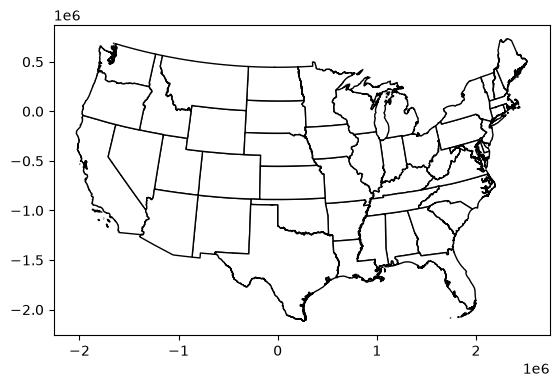

In [8]:
# US county and state boundaries

states = gpd.read_file(url_0+url_state)
contiguous_us = states.loc[
    ~states["STUSPS"].isin(["AK", "HI", "PR", "VI", "GU", "MP", "AS"])
]

contiguous_us = contiguous_us.to_crs(epsg=2163)
contiguous_us.plot(edgecolor="black", facecolor="white")

In [9]:
# filtering only needed columns
final_us = contiguous_us[["GEOID", "NAME", "STATEFP", "geometry"]].copy()
final_us

,GEOID,NAME,STATEFP,geometry
0,35,New Mexico,35,"POLYGON ((-862284.832 -1454476.3, -862055.894 ..."
1,46,South Dakota,46,"POLYGON ((-318904.047 7722.249, -318345.973 77..."
2,06,California,06,"MULTIPOLYGON (((-1717362.709 -1090134.236, -17..."
3,21,Kentucky,21,"MULTIPOLYGON (((946128.073 -881437.42, 946563...."
4,01,Alabama,01,"MULTIPOLYGON (((1149241.382 -1527641.924, 1149..."
5,13,Georgia,13,"MULTIPOLYGON (((1774030.6 -1324555.678, 177416..."
6,05,Arkansas,05,"POLYGON ((482000.986 -928930.836, 482025.138 -..."
7,42,Pennsylvania,42,"POLYGON ((1619194.622 -262054.08, 1619096.16 -..."
8,29,Missouri,29,"POLYGON ((357015.839 -482423.567, 357411.771 -..."
9,08,Colorado,08,"POLYGON ((-786661.937 -668512.657, -785229.222..."


In [10]:
# selecting only transmission within us

# combine US boundaries into one geometry
us_boundary = final_us.geometry.union_all()

# Select transmission lines within US
us_transmission = transmission[transmission.geometry.within(us_boundary)]

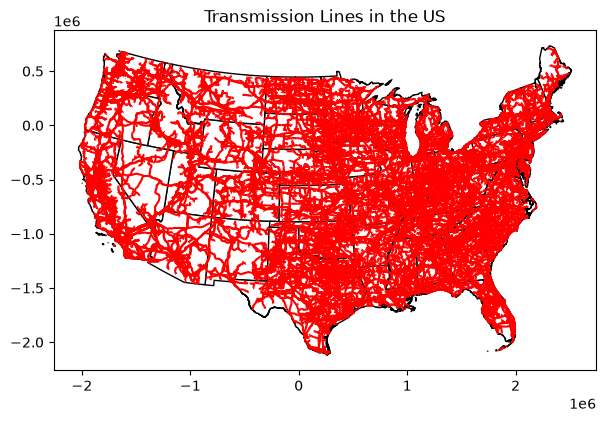

In [11]:
fig, ax = plt.subplots(figsize=(7,7))
final_us.plot(ax=ax, color="white", edgecolor="black")
us_transmission.plot(ax=ax, color="red")
ax.set_title("Transmission Lines in the US")
plt.show()

## Selecting transmission lines labeled "Not Available"

In [12]:
transmission_2163["STATUS"]
unavail_transmission = transmission_2163[transmission_2163["STATUS"] == 'NOT AVAILABLE']
unavail_transmission = unavail_transmission[["ID", "geometry"]].copy()
unavail_transmission

# Select unavailable transmission lines within US
unavail_transmission_f= unavail_transmission[unavail_transmission.geometry.within(us_boundary)]

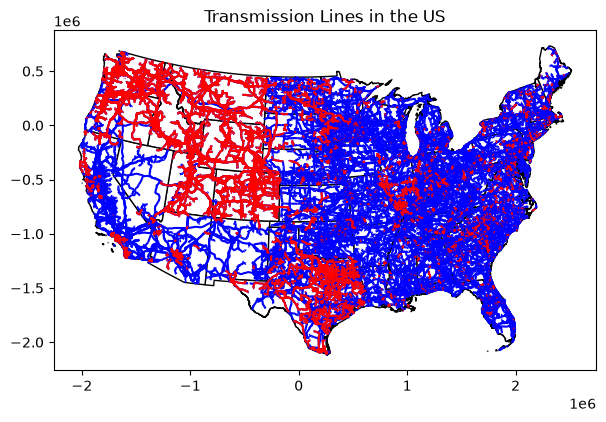

In [ ]:
fig, ax = plt.subplots(figsize=(7,7))
final_us.plot(ax=ax, color="white", edgecolor="black")
us_transmission.plot(ax=ax, color="blue")
unavail_transmission_f.plot(ax=ax, color="red")
ax.set_title("Transmission Lines in the US")
plt.show()

## Selecting transmission lines with no voltage listed

In [14]:
unavail_voltage = transmission_2163[transmission_2163["VOLT_CLASS"] == 'NOT AVAILABLE']
unavail_voltage = unavail_voltage[["ID", "geometry"]].copy()
unavail_voltage

# Select unavailable transmission lines within US
unavail_voltage_f= unavail_voltage[unavail_voltage.geometry.within(us_boundary)]

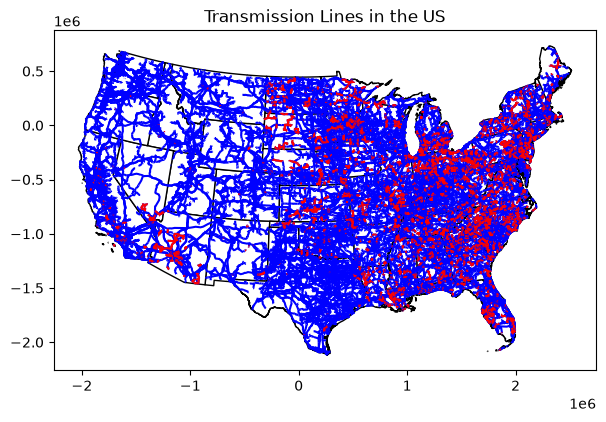

In [15]:
fig, ax = plt.subplots(figsize=(7,7))
final_us.plot(ax=ax, color="white", edgecolor="black")
us_transmission.plot(ax=ax, color="blue")
unavail_voltage_f.plot(ax=ax, color="red")
ax.set_title("Transmission Lines in the US")
plt.show()

## Selecting Voltage

In [21]:
selected_voltage = transmission_2163[transmission_2163["VOLTAGE"] >= 69]
selected_voltage = selected_voltage[["ID", "geometry"]].copy()
selected_voltage

# Select unavailable transmission lines within US
selected_voltage_f = selected_voltage[selected_voltage.geometry.within(us_boundary)]

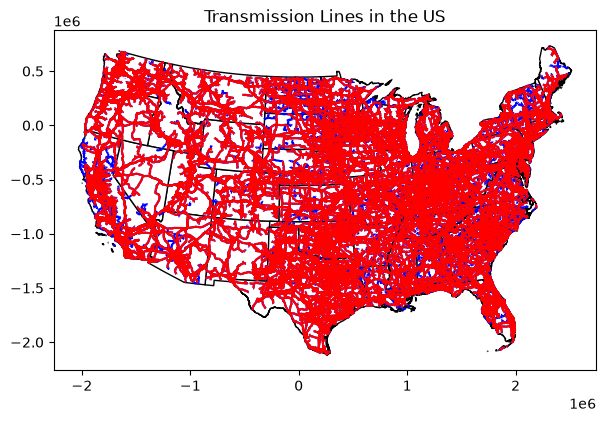

In [23]:
fig, ax = plt.subplots(figsize=(7,7))
final_us.plot(ax=ax, color="white", edgecolor="black")
us_transmission.plot(ax=ax, color="blue")
selected_voltage_f.plot(ax=ax, color="red")
ax.set_title("Transmission Lines in the US")
plt.show()

## Final Cleaning (Separating Datasets)

In [ ]:
# Select columns
transmission = transmission_2163[["ID", "VOLTAGE", "geometry"]].copy()

# voltage values to numeric
transmission["VOLTAGE"] = pd.to_numeric(transmission["VOLTAGE"], errors="coerce")

In [33]:
# Combine US boundaries into one geometry
us_boundary = final_us.geometry.union_all()

# Select transmission lines intersecting contiguous US
us_transmission = transmission[transmission.geometry.intersects(us_boundary)].copy()

In [34]:
# transmission lines from 69 kV to under 115 kV
transmission_69_114 = us_transmission[
    (us_transmission["VOLTAGE"] >= 69) &
    (us_transmission["VOLTAGE"] < 115)
].copy()

# transmission lines from 115 kV to under 230 kV
transmission_115_229 = us_transmission[
    (us_transmission["VOLTAGE"] >= 115) &
    (us_transmission["VOLTAGE"] < 230)
].copy()

# transmission lines 230 kV and above
transmission_230_plus = us_transmission[
    us_transmission["VOLTAGE"] >= 230
].copy()

In [36]:
# export as geojson file

transmission_69_114.to_crs(epsg=4326).to_file("data/transmission_69_114.geojson")

transmission_115_229.to_crs(epsg=4326).to_file("data/transmission_115_229.geojson")

transmission_230_plus.to_crs(epsg=4326).to_file("data/transmission_230_plus.geojson")